<a href="https://colab.research.google.com/github/Ashwini9713/fundamentals-of-ML/blob/main/exp_19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Accuracy: 1.0
              precision    recall  f1-score   support

    Rejected       1.00      1.00      1.00        30
    Approved       1.00      1.00      1.00       170

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200



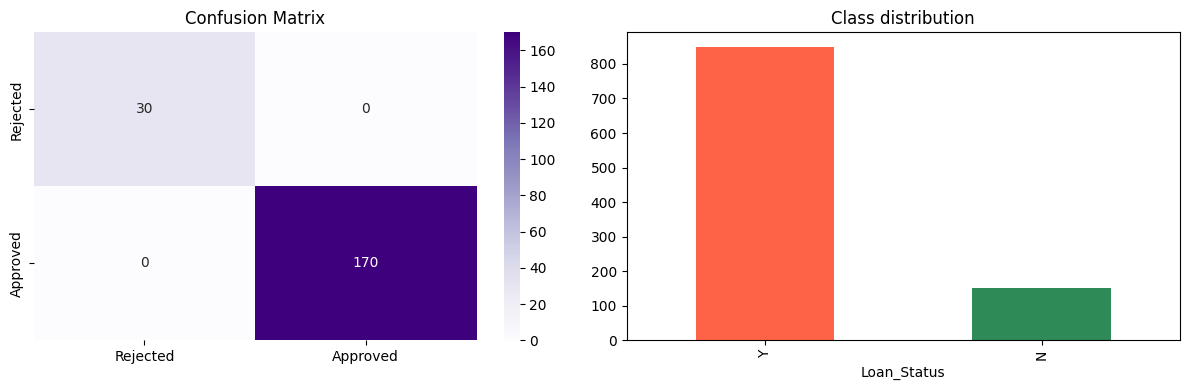

Sample applicant -> P(Rejected)=1.00, P(Approved)=0.00


In [2]:
if os.path.exists('loan.csv'):
    df = pd.read_csv('loan.csv').drop(columns=['Loan_ID'], errors='ignore')
    for c in df.columns:
        df[c] = df[c].fillna(df[c].mode()[0] if df[c].dtype == 'object' else df[c].median())
else:
    n = 1000
    df = pd.DataFrame({
        'Gender': np.random.choice(['Male', 'Female'], n, p=[.8, .2]),
        'Married': np.random.choice(['Yes', 'No'], n, p=[.65, .35]),
        'Education': np.random.choice(['Graduate', 'Not Graduate'], n, p=[.78, .22]),
        'ApplicantIncome': np.random.gamma(3, 1800, n).round(),
        'LoanAmount': np.random.normal(140, 50, n).clip(20, 400).round(),
        'Credit_History': np.random.choice([1, 0], n, p=[.85, .15]),
        'Property_Area': np.random.choice(['Urban', 'Semiurban', 'Rural'], n)})
    p = (0.15 + 0.6*df.Credit_History + 0.1*(df.Education == 'Graduate')
         + 0.05*(df.Property_Area == 'Semiurban') - 0.0003*df.LoanAmount + np.random.normal(0, .08, n))
    df['Loan_Status'] = np.where(p > 0.5, 'Y', 'N')

enc = df.copy()
for c in enc.select_dtypes('object').columns:
    enc[c] = LabelEncoder().fit_transform(enc[c])

X, y = enc.drop('Loan_Status', axis=1), enc['Loan_Status']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

from sklearn.naive_bayes import GaussianNB
nb = GaussianNB().fit(X_tr, y_tr)
pred = nb.predict(X_te)
print('Accuracy:', round(accuracy_score(y_te, pred), 4))
print(classification_report(y_te, pred, target_names=['Rejected', 'Approved']))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(confusion_matrix(y_te, pred), annot=True, fmt='d', cmap='Purples', ax=ax[0],
            xticklabels=['Rejected', 'Approved'], yticklabels=['Rejected', 'Approved'])
ax[0].set_title('Confusion Matrix')
df['Loan_Status'].value_counts().plot.bar(ax=ax[1], title='Class distribution', color=['tomato', 'seagreen'])
plt.tight_layout(); plt.show()

proba = nb.predict_proba(X_te.iloc[[0]])[0]
print(f'Sample applicant -> P(Rejected)={proba[0]:.2f}, P(Approved)={proba[1]:.2f}')

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             mean_squared_error, r2_score, mean_absolute_error)
np.random.seed(42)